# BIOT 6900 · Module 7 · Knowledge Graph — Alzheimer's disease

**Sharath Mandula** · Part I disease: **Alzheimer's disease**

This graph is built from my own earlier modules:
- **Module 2** — gene list and evidence (`targets_ad.csv`: RNA, protein, GWAS, multi-evidence score)
- **Module 3** — Ensembl/UniProt IDs and ESM C tractability priors (`p_sm`, `p_ab`); ESM-2 scores for APOE ε4/ε2
- **Module 4** — AlphaFold/fpocket structure calls for SAMHD1 and APOE
- **Module 6** — AD polygenic score PGS000334 SNPs (mapped to genes with my Module 2 GWAS file), and a 30-person patient layer with APOE genotype and PRS (real 1000 Genomes genotypes, **simulated** case/control status)

Module 5 was a CYP2C19 pharmacogene exercise (not AD), so no variants come from it.

**Setup:** run `prepare_module7_data.py` once to build `data/`, put the AuraDB credentials file here as `neo4j_credentials.txt` (git-ignored), then **Kernel → Restart & Run All**.

## 0 · Install and connect

Run this, then paste your Neo4j connection details into the next cell. On AuraDB
Free the **username is your instance ID**, not `neo4j`.

In [1]:
# If the kernel restarts after installing, run the cells again from the top.
%pip install neo4j networkx matplotlib pandas requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
from neo4j import GraphDatabase
import os

# Credentials are read from a git-ignored file so they never get committed.
# Put the AuraDB credentials .txt you downloaded next to this notebook and name it
# neo4j_credentials.txt (it has lines like NEO4J_URI=..., NEO4J_USERNAME=..., NEO4J_PASSWORD=...).
# Add "neo4j_credentials.txt" to your .gitignore.
def read_creds(path="neo4j_credentials.txt"):
    creds = {}
    if os.path.exists(path):
        for line in open(path, encoding="utf-8"):
            line = line.strip()
            if "=" in line and not line.startswith("#"):
                k, v = line.split("=", 1)
                creds[k.strip()] = v.strip()
    return creds

_c = read_creds()
NEO4J_URI      = _c.get("NEO4J_URI",      "neo4j+s://YOUR-INSTANCE.databases.neo4j.io")
NEO4J_USER     = _c.get("NEO4J_USERNAME", "YOUR-INSTANCE-ID")   # instance ID, not "neo4j"
NEO4J_PASSWORD = _c.get("NEO4J_PASSWORD", "YOUR-PASSWORD")

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))

def run_query(cypher, **params):
    with driver.session() as session:
        return [r.data() for r in session.run(cypher, **params)]

try:
    driver.verify_connectivity(); print("Connected to Neo4j as", NEO4J_USER)
except Exception as e:
    print("Not connected yet — check neo4j_credentials.txt (URI/username/password). Details:", e)


Connected to Neo4j as a770740d


In [3]:
     # Clear old lab data so only my Alzheimer's graph is in the database
     run_query("MATCH (n) DETACH DELETE n")
     print("database cleared:", run_query("MATCH (n) RETURN count(n) AS n")[0]["n"], "nodes left")

database cleared: 0 nodes left


## 1 · My data

Gene list = my Module 2 top 15, plus APP and GRIN2B (approved-drug targets, with my own Module 2 values), SORL1 and FERMT2 (genes of Module 6 PRS SNPs), and ACHE (pharmacology only — not in my Module 2 join). The related disease is **Aicardi-Goutières syndrome**, because my #1 gene SAMHD1 causes it.

The patient layer (30 people, 6 per ancestry) comes from Module 6. Patients link to the APOE variant they carry (`CARRIES`), which enables the stratification queries in §6b.

In [4]:
import pandas as pd
import networkx as nx
import os

# ===========================================================================
# MY DISEASE: Alzheimer's disease — built from my own Modules 2, 3, 4 and 6.
# data/ is made by prepare_module7_data.py (run it once; see README).
#   targets_ad.csv            Module 2  multi-omics ranking (RNA + protein + GWAS)
#   targets_ad_w3.csv         Module 3  ESM C tractability priors (p_sm, p_ab)
#   structure_assessment_ad   Module 4  AlphaFold + fpocket calls (SAMHD1, APOE)
#   pgs000334_variants.csv    Module 6  AD polygenic score SNPs, mapped with my GWAS file
#   anchor_variants.csv       Module 3  ESM-2 zero-shot scores for APOE e4 / e2
#   gene_ids.csv              Module 3  proteome.tsv (Ensembl + UniProt IDs)
# (Module 5 was a CYP2C19 pharmacogene exercise, not AD, so no variants come from it.)
# ===========================================================================
DISEASE = "Alzheimer's disease"
TOP_N   = 15

def _none(x):                        # Neo4j wants None, not NaN
    return None if pd.isna(x) else x

tgt = pd.read_csv("data/targets_ad.csv")
tgt["m2_rank"] = range(1, len(tgt) + 1)            # file is already sorted by my score
w3  = pd.read_csv("data/targets_ad_w3.csv").set_index("gene")
ids = pd.read_csv("data/gene_ids.csv").drop_duplicates("gene").set_index("gene")
pgs = pd.read_csv("data/pgs000334_variants.csv")

# Genes = my Module 2 top 15
#       + APP and GRIN2B (drug targets, with MY Module 2 values: ranks 19 and 358)
#       + SORL1 and FERMT2 (genes of Module 6 PRS SNPs that map inside a gene body)
# APOE and CLU already carry PRS SNPs and are in the top 15.
EXTRA_FROM_MY_DATA = ["APP", "GRIN2B", "SORL1", "FERMT2"]
sel = pd.concat([tgt.head(TOP_N), tgt[tgt["gene"].isin(EXTRA_FROM_MY_DATA)]])

def gene_tuple(r):
    dg = None
    if r["gene"] in w3.index:                      # best-modality prior (Module 3)
        dg = round(float(max(w3.loc[r["gene"], "p_sm"], w3.loc[r["gene"], "p_ab"])), 3)
    ens = ids.loc[r["gene"], "ensembl_gene"] if r["gene"] in ids.index else ""
    # gwas_p_floored: APOE/APOC1 are 0 in the GWAS Catalog (underflow) -> 1e-295, as in Module 2
    return (r["gene"], ens, _none(r["gwas_p_floored"]), _none(r["rna_lfc"]),
            _none(r["prot_lfc"]), dg)

GENES = [gene_tuple(r) for _, r in sel.iterrows()]
# ACHE: target of donepezil/rivastigmine/galantamine. NOT in my Module 2 join,
# so it enters on pharmacology alone (no omics or GWAS values).
GENES.append(("ACHE", ids.loc["ACHE", "ensembl_gene"], None, None, None, None))
print(f"{len(GENES)} genes:", [g[0] for g in GENES])

# Extra gene properties from my earlier modules (added to the nodes after the build)
GENE_EXTRA = {}
for _, r in sel.iterrows():
    GENE_EXTRA[r["gene"]] = {"m2_rank": int(r["m2_rank"]), "m2_score": round(float(r["score"]), 3),
                             "rna_p": _none(r["rna_p"]), "prot_p": _none(r["prot_p"]),
                             "concordant": bool(r["concordant"])}
for g in w3.index:
    if g in GENE_EXTRA:
        GENE_EXTRA[g].update(m3_rank=int(w3.loc[g, "rank"]), p_sm=round(float(w3.loc[g, "p_sm"]), 3),
                             p_ab=round(float(w3.loc[g, "p_ab"]), 3))
for g in GENE_EXTRA:
    if g in ids.index: GENE_EXTRA[g]["uniprot"] = ids.loc[g, "accession"]
st = pd.read_csv("data/structure_assessment_ad.csv").set_index("gene")     # Module 4
for g in st.index:
    GENE_EXTRA[g].update(pdb_id=st.loc[g, "pdb_id"], af_mean_plddt=float(st.loc[g, "mean_pLDDT"]),
                         best_pocket_score=float(st.loc[g, "best_pocket_score"]),
                         structure_call=st.loc[g, "druggability_call"])

# --- Phenotypes (HPO terms) ---
PHENOTYPES = [
    "Dementia",                 # HP:0000726
    "Memory impairment",        # HP:0002354
    "Cognitive impairment",     # HP:0100543
    "Cerebral atrophy",         # HP:0002059
    "Neurofibrillary tangles",  # HP:0002185
]

# --- Pathways (Reactome; the last one is a GO-level grouping, flagged in the report) ---
PATHWAYS = [
    "Amyloid fiber formation",
    "Plasma lipoprotein assembly, remodeling, and clearance",
    "Regulation of Complement cascade",
    "Nucleotide catabolism",
    "Interferon alpha/beta signaling",
    "Trafficking of AMPA receptors",
    "Activation of NMDA receptors and postsynaptic events",
    "Neurotransmitter clearance",
    "Complex I biogenesis",
    "Collagen formation",
    "RHO GTPase cycle",
    "Endosomal sorting (GO grouping)",
]
GENE_IN_PATHWAY = {
    "Amyloid fiber formation": ["APP"],
    "Plasma lipoprotein assembly, remodeling, and clearance": ["APOE", "APOC1"],
    "Regulation of Complement cascade": ["CLU"],
    "Nucleotide catabolism": ["SAMHD1"],
    "Interferon alpha/beta signaling": ["JAK1"],            # JAK1 is added with the related disease
    "Trafficking of AMPA receptors": ["CACNG8"],
    "Activation of NMDA receptors and postsynaptic events": ["GRIN2B"],
    "Neurotransmitter clearance": ["ACHE"],
    "Complex I biogenesis": ["NDUFA10"],
    "Collagen formation": ["COL11A1"],
    "RHO GTPase cycle": ["RHOJ", "FARP2"],
    "Endosomal sorting (GO grouping)": ["SORL1"],
}

# --- Drugs (Open Targets known drugs / ChEMBL): drug -> target gene, status ---
DRUGS = [
    ("Donepezil",    "ACHE",   "approved"),
    ("Rivastigmine", "ACHE",   "approved"),
    ("Galantamine",  "ACHE",   "approved"),
    ("Memantine",    "GRIN2B", "approved"),
    ("Lecanemab",    "APP",    "approved"),         # anti-amyloid-beta antibody
    ("Donanemab",    "APP",    "approved"),         # anti-amyloid-beta antibody
    ("Semorinemab",  "MAPT",   "investigational"),  # anti-tau antibody (discussed in my Module 3 report)
]

# --- Variants: Module 6 PGS000334 SNPs whose gene is in my graph ---
anch = pd.read_csv("data/anchor_variants.csv")
ESM2 = {"rs429358": float(anch.loc[anch.variant == "C130R", "score"].iloc[0]),   # APOE e4
        "rs7412":   float(anch.loc[anch.variant == "R176C", "score"].iloc[0])}   # APOE e2
VARIANTS, VARIANT_EXTRA = [], {}
for _, r in pgs[pgs["graph_gene"].notna()].iterrows():
    gene = r["graph_gene"]
    edge_ev = {"source": "GWAS Catalog MAPPED_GENE (my Module 2 file)",
               "intergenic": bool(r["intergenic"]), "mapped_gene": r["mapped_gene"]}
    VARIANTS.append((r["variant"], gene, edge_ev))
    gp = r["gwas_p"] if r["gwas_p"] > 0 else 1e-295
    VARIANT_EXTRA[r["variant"]] = {"pgs_weight": float(r["weight"]), "effect_allele": r["effect_allele"],
                                   "gwas_p": float(gp), "source": "PGS000334 (Module 6)",
                                   "esm2_score": ESM2.get(r["variant"])}
# keep a variant only if its gene is a node (intergenic BIN1/ADAM10/CNN2/PSMC3 SNPs drop out)
VARIANTS = [v for v in VARIANTS if v[1] in {g[0] for g in GENES}]

# --- Related disease: Aicardi-Goutieres syndrome (AGS) ---
# My #1 gene SAMHD1 is an AGS gene (loss of function -> type I interferon disease).
# AGS shares cognitive impairment and cerebral atrophy with AD.
# Baricitinib (JAK1/2 inhibitor) is used to treat AGS.
RELATED = {
    "name":   "Aicardi-Goutieres syndrome",
    "shares": ["Cognitive impairment", "Cerebral atrophy"],
    # (symbol, ensembl, edge evidence)
    "genes":  [("SAMHD1", ids.loc["SAMHD1", "ensembl_gene"], {"source": "Mendelian (AGS5, OMIM)", "pvalue": None}),
               ("JAK1",   ids.loc["JAK1", "ensembl_gene"],   {"source": "drug-target evidence (baricitinib treats AGS)", "pvalue": None})],
    "drugs":  [("Baricitinib", "JAK1", "approved (RA); investigational in AGS")],
}

# --- Patient layer from Module 6 (30 people, 6 per ancestry, seed 6900) ---
# APOE genotype and PGS000334 PRS are computed from 1000 Genomes genotypes; IDs are
# pseudonyms (PT01...). The case/control STATUS IS SIMULATED (1000 Genomes has no disease labels).
pts = pd.read_csv("data/patients_m6.csv")
PATIENTS = [(r.patient_id, float(r.age), r.apoe_genotype, float(r.prs_percentile), r.status)
            for r in pts.itertuples()]
PATIENT_EXTRA = {r.patient_id: {"ancestry": r.ancestry, "prs_z": float(r.prs_z),
                                "source": "1000 Genomes genotype (Module 6); SIMULATED phenotype"}
                 for r in pts.itertuples()}

# ---------------------------------------------------------------------------
# Build node/edge collections. Two small edits to the starter, both so the
# evidence on each edge is correct: (1) variant edges carry their mapping evidence;
# (2) related-disease genes keep their existing node and get their own edge source.
# ---------------------------------------------------------------------------
NODES, EDGES = {}, []
def add_node(n, k, **p): NODES[n] = dict(kind=k, **p)
def add_edge(s, r, d, **p): EDGES.append(dict(src=s, rel=r, dst=d, **p))

add_node(DISEASE, "disease")
for sym, ens, gp, rna, prot, dg in GENES:
    add_node(sym, "gene", ensembl=ens, gwas_p=gp, rna_lfc=rna, prot_lfc=prot, druggability=dg)
    add_edge(sym, "ASSOCIATED_WITH", DISEASE, pvalue=gp,
             source=("Module 2: GWAS + RNA + protein" if gp else "pharmacology only"))
for ph in PHENOTYPES:
    add_node(ph, "phenotype"); add_edge(DISEASE, "HAS_PHENOTYPE", ph)
_r = RELATED
add_node(_r["name"], "disease")
for ph in _r["shares"]:
    if ph not in NODES: add_node(ph, "phenotype")
    add_edge(_r["name"], "HAS_PHENOTYPE", ph)
for sym, ens, ev in _r["genes"]:
    if sym not in NODES: add_node(sym, "gene", ensembl=ens)          # edit (2)
    add_edge(sym, "ASSOCIATED_WITH", _r["name"], **ev)
for name, tgt_gene, status in _r["drugs"]:
    add_node(name, "drug", status=status); add_edge(name, "TARGETS", tgt_gene)
for pw in PATHWAYS:
    add_node(pw, "pathway")
for pw, gl in GENE_IN_PATHWAY.items():
    for g in gl:
        if g in NODES: add_edge(g, "PARTICIPATES_IN", pw)
for name, tgt_gene, status in DRUGS:
    add_node(name, "drug", status=status); add_edge(name, "TARGETS", tgt_gene)
for v, g, ev in VARIANTS:                                            # edit (1)
    add_node(v, "variant", **VARIANT_EXTRA[v]); add_edge(v, "OCCURS_IN", g, **ev)
for pid, age, geno, prs, status in PATIENTS:
    add_node(pid, "patient", age=age, apoe_genotype=geno, prs_percentile=prs, status=status,
             **PATIENT_EXTRA[pid])
    if "e4" in geno: add_edge(pid, "CARRIES", "rs429358", copies=geno.count("e4"))   # APOE e4
    if "e2" in geno: add_edge(pid, "CARRIES", "rs7412",   copies=geno.count("e2"))   # APOE e2
for g, extra in GENE_EXTRA.items():
    if g in NODES: NODES[g].update(extra)

print("nodes:", len(NODES), " edges:", len(EDGES))
print("disease:", DISEASE)


20 genes: ['SAMHD1', 'PDZD2', 'ZMYM2', 'APOE', 'ASAP1', 'CACNG8', 'COL11A1', 'MAPT', 'APOC1', 'RHOJ', 'NDUFA10', 'WNK2', 'CLU', 'FARP2', 'NUMA1', 'APP', 'GRIN2B', 'SORL1', 'FERMT2', 'ACHE']
nodes: 83  edges: 67
disease: Alzheimer's disease


## 2 · Load into Neo4j

Provided — no edits needed. Creates a uniqueness constraint, then loads your
nodes and relationships with batched `UNWIND` + `MERGE`.

In [5]:
run_query("CREATE CONSTRAINT entity_name IF NOT EXISTS "
          "FOR (n:Entity) REQUIRE n.name IS UNIQUE")

KIND_LABEL = {"gene":"Gene","disease":"Disease","phenotype":"Phenotype",
              "pathway":"Pathway","drug":"Drug","variant":"Variant","patient":"Patient"}

for kind, label in KIND_LABEL.items():
    rows = [dict(name=n, **{k: v for k, v in d.items() if k != "kind"})
            for n, d in NODES.items() if d["kind"] == kind]
    if rows:
        run_query(f"UNWIND $rows AS row MERGE (e:{label}:Entity {{name: row.name}}) SET e += row",
                  rows=rows)

from collections import defaultdict
by_rel = defaultdict(list)
for e in EDGES:
    by_rel[e["rel"]].append({"src": e["src"], "dst": e["dst"],
                             "props": {k: v for k, v in e.items() if k not in ("src","dst","rel")}})
for rel, rows in by_rel.items():
    run_query(f"""UNWIND $rows AS row
                  MATCH (a:Entity {{name: row.src}})
                  MATCH (b:Entity {{name: row.dst}})
                  MERGE (a)-[r:{rel}]->(b)
                  SET r += row.props""", rows=rows)

print("node counts:", run_query("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC"))
print("relationships:", run_query("MATCH ()-[r]->() RETURN count(r) AS n")[0]["n"])

node counts: [{'label': 'Entity', 'n': 83}]
relationships: 67


## 3 · A quick look

Provided. Open your instance in the Aura console and run
`MATCH (n) RETURN n LIMIT 100` to see the graph you just loaded, or use §7 to draw it.

## 4 · Query it — the opening question (Cypher)

Provided. These answer the opening question for whatever `DISEASE` you set in §1.

> **TODO (report):** after running, note which drugs come back, and for the
> repurposing query, which related disease and shared symptom produced each hit.

In [6]:
# 2 hops: drugs acting on genes associated with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(dis:Disease)
    WHERE dis.name = $disease
    RETURN d.name AS drug, g.name AS gene, d.status AS status
    ORDER BY drug
""", disease=DISEASE)

[{'drug': 'Donanemab', 'gene': 'APP', 'status': 'approved'},
 {'drug': 'Donepezil', 'gene': 'ACHE', 'status': 'approved'},
 {'drug': 'Galantamine', 'gene': 'ACHE', 'status': 'approved'},
 {'drug': 'Lecanemab', 'gene': 'APP', 'status': 'approved'},
 {'drug': 'Memantine', 'gene': 'GRIN2B', 'status': 'approved'},
 {'drug': 'Rivastigmine', 'gene': 'ACHE', 'status': 'approved'},
 {'drug': 'Semorinemab', 'gene': 'MAPT', 'status': 'investigational'}]

In [7]:
# 5 hops: drugs on genes of diseases that SHARE A SYMPTOM with your disease
run_query("""
    MATCH (d:Drug)-[:TARGETS]->(g:Gene)-[:ASSOCIATED_WITH]->(other:Disease)
          -[:HAS_PHENOTYPE]->(p:Phenotype)<-[:HAS_PHENOTYPE]-(ad:Disease)
    WHERE ad.name = $disease AND other <> ad
    RETURN d.name AS repurposing_candidate, g.name AS gene,
           other.name AS via_disease, collect(DISTINCT p.name) AS shared_symptoms
    ORDER BY repurposing_candidate
""", disease=DISEASE)

[{'repurposing_candidate': 'Baricitinib',
  'gene': 'JAK1',
  'via_disease': 'Aicardi-Goutieres syndrome',
  'shared_symptoms': ['Cognitive impairment', 'Cerebral atrophy']}]

## 5 · Biomarker prioritization (centrality)

Provided. PageRank fused with your gene evidence.

> **TODO (report):** which genes rank highest? Does that match the biology you
> expect for your disease? Flag any non-obvious hit.

In [8]:
# PageRank in NetworkX, fused with your gene evidence (runs on any Neo4j tier).
G = nx.DiGraph()
for name, d in NODES.items():
    G.add_node(name, **d)
for e in EDGES:
    G.add_edge(e["src"], e["dst"], **{k: v for k, v in e.items() if k not in ("src", "dst")})

pr = nx.pagerank(G)
rows = [{"gene": n, "pagerank": round(pr[n], 4), "gwas_p": d.get("gwas_p"),
         "druggability": d.get("druggability")}
        for n, d in G.nodes(data=True) if d["kind"] == "gene"]
biomarkers = pd.DataFrame(rows).sort_values("pagerank", ascending=False)
print("Candidate biomarkers for", DISEASE, "(PageRank + evidence):")
print(biomarkers.to_string(index=False))


Candidate biomarkers for Alzheimer's disease (PageRank + evidence):
   gene  pagerank        gwas_p  druggability
   APOE    0.0646 1.000000e-295         0.016
   ACHE    0.0215           NaN           NaN
    APP    0.0164  2.000000e-14           NaN
    CLU    0.0112  1.000000e-47         0.131
   MAPT    0.0112  9.000000e-16         0.006
 GRIN2B    0.0112  3.000000e-06           NaN
  SORL1    0.0112  1.000000e-22           NaN
   JAK1    0.0112           NaN           NaN
 FERMT2    0.0112  8.000000e-16           NaN
  ASAP1    0.0061  2.000000e-13         0.193
  ZMYM2    0.0061  3.000000e-19         0.040
  PDZD2    0.0061  1.000000e-21         0.020
 SAMHD1    0.0061  2.000000e-36         0.824
   WNK2    0.0061  4.000000e-16         0.057
NDUFA10    0.0061  1.000000e-10         0.055
   RHOJ    0.0061  6.000000e-11         0.034
  APOC1    0.0061 1.000000e-295         0.248
 CACNG8    0.0061  2.000000e-10         0.380
COL11A1    0.0061  1.000000e-09         0.100
  FARP2    0

### 5b · Same ranking, undirected

Directed PageRank only rewards incoming edges, so I also rank on the undirected graph for the report.

In [9]:
# Extra check for the report: PageRank on the UNDIRECTED graph. Directed PageRank only
# rewards incoming edges (drugs -> gene), so genes whose evidence points outward
# (gene -> disease, gene -> pathway) are under-counted.
pr_u = nx.pagerank(G.to_undirected())
biomarkers["pagerank_undirected"] = biomarkers["gene"].map(lambda g: round(pr_u[g], 4))
biomarkers["degree"] = biomarkers["gene"].map(lambda g: G.to_undirected().degree(g))
print(biomarkers.sort_values("pagerank_undirected", ascending=False).to_string(index=False))


   gene  pagerank        gwas_p  druggability  pagerank_undirected  degree
   ACHE    0.0215           NaN           NaN               0.0357       5
    APP    0.0164  2.000000e-14           NaN               0.0287       4
   APOE    0.0646 1.000000e-295         0.016               0.0252       4
   JAK1    0.0112           NaN           NaN               0.0218       3
    CLU    0.0112  1.000000e-47         0.131               0.0217       3
  SORL1    0.0112  1.000000e-22           NaN               0.0217       3
 GRIN2B    0.0112  3.000000e-06           NaN               0.0217       3
 SAMHD1    0.0061  2.000000e-36         0.824               0.0192       3
   MAPT    0.0112  9.000000e-16         0.006               0.0146       2
 FERMT2    0.0112  8.000000e-16           NaN               0.0146       2
COL11A1    0.0061  1.000000e-09         0.100               0.0146       2
 CACNG8    0.0061  2.000000e-10         0.380               0.0146       2
NDUFA10    0.0061  1.0000

## 6 · Communities

Provided. Modularity clustering groups densely connected nodes.

> **TODO (report):** pick ONE community and read it as a subtype or mechanism
> hypothesis.

In [10]:
from networkx.algorithms.community import greedy_modularity_communities
comms = greedy_modularity_communities(G.to_undirected())
print(f"{len(comms)} communities:")
for i, c in enumerate(comms):
    print(f"  {i}: {sorted(c)}")


31 communities:
  0: ['ASAP1', "Alzheimer's disease", 'COL11A1', 'Collagen formation', 'Complex I biogenesis', 'Dementia', 'FARP2', 'Memory impairment', 'NDUFA10', 'NUMA1', 'Neurofibrillary tangles', 'PDZD2', 'RHO GTPase cycle', 'RHOJ', 'WNK2', 'ZMYM2']
  1: ['APOC1', 'APOE', 'PT04', 'PT08', 'PT13', 'PT18', 'PT29', 'Plasma lipoprotein assembly, remodeling, and clearance', 'rs7412']
  2: ['Aicardi-Goutieres syndrome', 'Baricitinib', 'Cerebral atrophy', 'Cognitive impairment', 'Interferon alpha/beta signaling', 'JAK1', 'Nucleotide catabolism', 'SAMHD1']
  3: ['PT02', 'PT03', 'PT07', 'PT12', 'PT26', 'PT30', 'rs429358']
  4: ['ACHE', 'Donepezil', 'Galantamine', 'Neurotransmitter clearance', 'Rivastigmine']
  5: ['APP', 'Amyloid fiber formation', 'Donanemab', 'Lecanemab']
  6: ['Activation of NMDA receptors and postsynaptic events', 'GRIN2B', 'Memantine']
  7: ['CLU', 'Regulation of Complement cascade', 'rs11136000']
  8: ['Endosomal sorting (GO grouping)', 'SORL1', 'rs11218343']
  9: ['CAC

### 6b · Patient stratification (Cypher)

The patient-characteristics layer: APOE-genotype groups and ancestry groups from my Module 6 cohort. Genotypes and PRS are real; **case/control status is simulated**, so case rates are illustrative only.

In [11]:
# Patient stratification (Cypher, in Neo4j): APOE genotype groups vs case rate and PRS.
# Remember: genotypes and PRS are real (1000 Genomes); case/control status is SIMULATED.
pd.DataFrame(run_query("""
    MATCH (p:Patient)
    RETURN p.apoe_genotype AS genotype, count(*) AS n,
           sum(CASE WHEN p.status = 'case' THEN 1 ELSE 0 END) AS cases,
           round(avg(p.prs_percentile), 1) AS mean_prs_percentile
    ORDER BY mean_prs_percentile DESC
"""))


,genotype,n,cases,mean_prs_percentile
0,e3/e4,6,4,82.4
1,e3/e3,19,4,37.6
2,e2/e3,5,2,9.7


In [12]:
# Who carries each APOE allele, and from which ancestry? (variant-level link)
pd.DataFrame(run_query("""
    MATCH (p:Patient)-[c:CARRIES]->(v:Variant)-[:OCCURS_IN]->(g:Gene)
    RETURN v.name AS variant, g.name AS gene, count(p) AS n_carriers,
           collect(p.name + ' (' + p.ancestry + ', ' + p.status + ')') AS carriers
"""))


,variant,gene,n_carriers,carriers
0,rs7412,APOE,5,"[PT04 (EUR, case), PT08 (AFR, control), PT13 (..."
1,rs429358,APOE,6,"[PT02 (EUR, case), PT03 (EUR, case), PT07 (AFR..."


In [13]:
# PRS by ancestry in my 30-person cohort (Module 6 portability, now inside the graph)
pd.DataFrame(run_query("""
    MATCH (p:Patient)
    RETURN p.ancestry AS ancestry, count(*) AS n,
           round(avg(p.prs_z), 2) AS mean_prs_z,
           sum(CASE WHEN p.status = 'case' THEN 1 ELSE 0 END) AS cases
    ORDER BY mean_prs_z DESC
"""))


,ancestry,n,mean_prs_z,cases
0,AFR,6,0.30,3
1,AMR,6,-0.08,2
2,EUR,6,-0.13,3
3,SAS,6,-0.74,2
4,EAS,6,-0.77,0


## 7 · Visualize and export

Provided. Draws your graph coloured by kind and exports your node/edge table.
Both the figure and the CSV are graded artifacts — commit them.

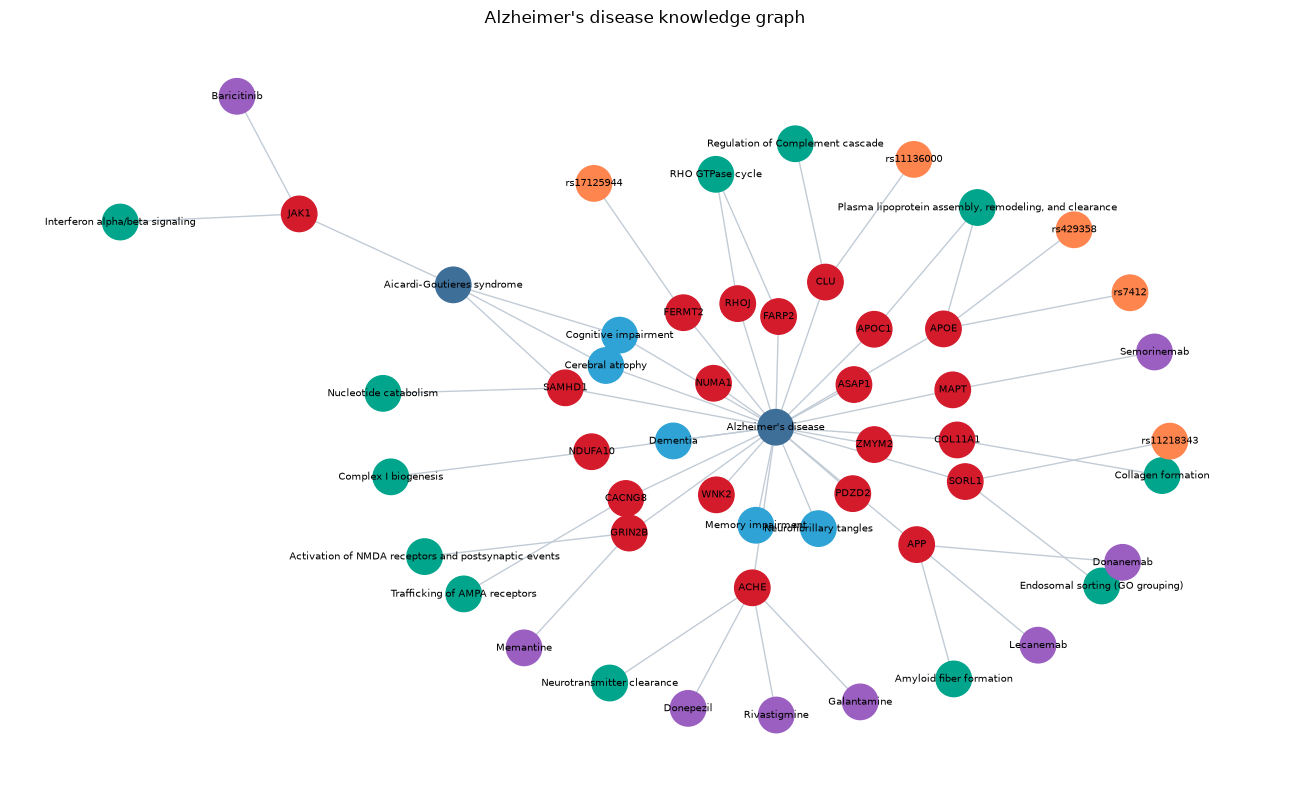

saved my_knowledge_graph.png, nodes.csv, edges.csv


In [14]:
import matplotlib.pyplot as plt

KIND_COLOR = {"gene":"#D41B2C","disease":"#3E6F99","phenotype":"#2FA3D6",
              "pathway":"#00A58C","drug":"#9A5FC0","variant":"#FF854F","patient":"#8A94A3"}
H = G.subgraph([n for n, d in G.nodes(data=True) if d["kind"] != "patient"])
pos = nx.kamada_kawai_layout(H.to_undirected())   # less tangled than spring_layout for this graph
plt.figure(figsize=(13, 8))
nx.draw_networkx_edges(H, pos, edge_color="#C2CCD6", width=1.0, arrows=False)
nx.draw_networkx_nodes(H, pos, node_size=650,
                       node_color=[KIND_COLOR[H.nodes[n]["kind"]] for n in H.nodes()])
nx.draw_networkx_labels(H, pos, font_size=7)
plt.axis("off"); plt.title(f"{DISEASE} knowledge graph"); plt.tight_layout()
plt.savefig("my_knowledge_graph.png", dpi=150, bbox_inches="tight")   # <- commit this
plt.show()

# export node and edge tables (commit the CSVs)
pd.DataFrame([dict(name=n, **d) for n, d in NODES.items()]).to_csv("nodes.csv", index=False)
pd.DataFrame(EDGES).to_csv("edges.csv", index=False)
print("saved my_knowledge_graph.png, nodes.csv, edges.csv")

## 8 · Your report (the 40%)

Write a **3–4 page report** answering these four, in your own words:

1. **Schema and evidence** — why these node and edge types, and what evidence you put on the edges.
2. **Top targets** — which genes rank highest by centrality (§5), and does that match the biology you expect? Any non-obvious hit?
3. **A hypothesis from a path** — one repurposing or shared-mechanism hypothesis a path in your graph suggests (§4), and what would test it.
4. **Limitations** — an edge is evidence, not truth. Which of your edges are weak, and how would the answer change with better data? Note where you used (or would use) AI to harmonize data or write queries, and how you checked it.

#### Submit
- This notebook (**Kernel → Restart & Run All** first; credentials in a git-ignored file, not committed).
- `my_knowledge_graph.png`, `nodes.csv`, `edges.csv`.
- Your 3–4 page report (PDF) and a short README (name + your disease).
- Push to your biot6900 repo and post the link on Canvas.

#### Reset (to start over)
```cypher
MATCH (n) DETACH DELETE n      // wipes the database — run deliberately
```
